# 07 — Единая недельная таблица: что известно до релиза EIA

Сводим источники в одну строку на релиз EIA так, чтобы каждый признак был известен **до**
публикации (среда, 10:30 ET). Смотрим покрытие, связь признаков с таргетом (сюрприз) и с
реакцией спрэда в день релиза, коллинеарность и устойчивость по периодам. Таблицу сохраняем
в `eda/data/derived/weekly_frame.parquet` — заготовка для M0/M4.

Данные: `eda_utils.release_frame()` (таргет, консенсус, API), `eia/eia_weekly_features.parquet`,
`eda/data/derived/curve_clean.parquet` (дневная кривая с разметкой роллов из ноутбука 04 —
запускать 04 раньше 07), `fred/fred_daily_features.parquet`,
`infrastructure/nhc_hurdat2_atlantic_2015_2025.parquet`,
`infrastructure/bsee_production_by_structure_2015plus.parquet`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import eda_utils as u

u.setup_style()
pd.set_option("display.max_colwidth", 90)
SPLIT = pd.Timestamp("2023-01-01")
DERIVED = u.EDA_DIR / "data" / "derived"
frame = u.release_frame()
R = frame["release_date"]

## 1. Правила доступности

| Блок | Значение для релиза в день R | Основание |
|:--|:--|:--|
| Таргет | `actual − consensus`, факт первой публикации | ноутбук 03 |
| Консенсус, API | значение недели отчёта; API — вторник 16:30 ET | ноутбук 03 |
| История EIA | неделя отчёта минус 1 (данные прошлого релиза) | ноутбук 02: потоки той же недели выходят вместе с запасами |
| Кривая WTI | закрытие торгового дня перед R; изменения same-contract | ноутбук 04 |
| FRED | ставки, breakeven, BAA — на R−2 рабочих дня; VIX — на R−1; USD — на пятницу недели отчёта | ноутбук 05 |
| Ураганы | трек HURDAT2 в прямоугольнике добычи залива за неделю отчёта | ноутбук 06; best track — не point-in-time |
| Добыча BSEE | месяц на 2 раньше месяца релиза | ноутбук 06; точный лаг публикации неизвестен |

Реакция спрэда и цены в день R — **исход**, а не признак: в модель для недели R она не входит.

## 2. Сборка таблицы

In [2]:
weekly = frame[["release_date", "period", "actual_mmbbl", "consensus_mmbbl", "surprise_mmbbl", "api_mmbbl"]].copy()
weekly["api_minus_consensus"] = weekly["api_mmbbl"] - weekly["consensus_mmbbl"]
# Прошлый релиз — факт первой публикации
weekly["actual_lag1"] = weekly["actual_mmbbl"].shift(1)
weekly["surprise_lag1"] = weekly["surprise_mmbbl"].shift(1)

# История EIA: неделя отчёта минус 1
eia = u.load("eia/eia_weekly_features.parquet").set_index("period").sort_index()
eia_lag = pd.DataFrame(
    {
        "cushing_change_lag1": eia["cushing_stocks_change_mmbbl"],
        "padd3_change_lag1": eia["padd3_stocks_change_mmbbl"],
        "gasoline_change_lag1": eia["gasoline_stocks_change_mmbbl"],
        "distillate_change_lag1": eia["distillate_stocks_change_mmbbl"],
        "refinery_util_lag1": eia["refinery_utilization"],
        "refinery_inputs_4w_lag1": eia["refinery_inputs"].diff(4),
        "cushing_level_lag1": eia["cushing_stocks_mmbbl"],
    },
)
eia_lag.index = eia_lag.index + pd.Timedelta(days=7)
weekly = weekly.merge(eia_lag, left_on="period", right_index=True, how="left")
weekly.filter(like="lag1").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
actual_lag1,615.0,0.07,5.39,-17.05,-3.54,-0.39,3.38,21.56
surprise_lag1,615.0,0.34,4.73,-15.68,-2.64,0.02,3.27,22.49
cushing_change_lag1,607.0,-0.03,1.41,-5.59,-0.93,-0.02,0.80,6.42
padd3_change_lag1,607.0,0.06,4.56,-15.57,-2.87,-0.25,2.68,20.86
gasoline_change_lag1,607.0,-0.05,3.19,-13.62,-2.11,-0.27,1.76,10.90
distillate_change_lag1,607.0,-0.04,2.79,-9.72,-1.90,-0.35,1.47,10.61
refinery_util_lag1,608.0,89.60,5.59,56.00,87.50,90.70,93.30,98.10
refinery_inputs_4w_lag1,604.0,8.52,792.75,-4738.00,-309.50,115.50,444.50,5038.00
cushing_level_lag1,608.0,40.68,15.24,18.60,25.82,36.93,55.81,69.42


In [3]:
curve = pd.read_parquet(DERIVED / "curve_clean.parquet").set_index("trading_day").sort_index()
trading = curve.index


def last_trading_before(dates: pd.Series) -> pd.DatetimeIndex:
    """Последний торговый день строго до даты."""

    return trading[np.searchsorted(trading, dates.to_numpy(), side="left") - 1]


prev = last_trading_before(R)
pos = trading.get_indexer(prev)
csum_spread = curve["dclean_f1_f2"].fillna(0).cumsum().to_numpy()
csum_f1 = curve["dF1_clean"].fillna(0).cumsum().to_numpy()
weekly["spread_f1_f2_prev"] = curve["spread_f1_f2"].to_numpy()[pos]
weekly["dspread_5d_prev"] = csum_spread[pos] - csum_spread[pos - 5]
weekly["dF1_5d_prev"] = csum_f1[pos] - csum_f1[pos - 5]
weekly["roll_window_release"] = curve["roll_window"].reindex(R).to_numpy()
# Исходы дня релиза (не признаки)
weekly["dspread_release"] = curve["dclean_f1_f2"].reindex(R).to_numpy()
weekly["dF1_release"] = curve["dF1_clean"].reindex(R).to_numpy()
print(f"релизов вне торговых дней Barchart: {weekly['dspread_release'].isna().sum()}")

релизов вне торговых дней Barchart: 0


In [4]:
fred = u.load("fred/fred_daily_features.parquet").set_index("date").sort_index()
business = pd.offsets.BDay


def fred_asof(column: str, cutoff: pd.Series) -> np.ndarray:
    """Последнее непустое значение колонки FRED не позже даты отсечки."""

    s = fred[column].dropna()
    idx = np.searchsorted(s.index, cutoff.to_numpy(), side="right") - 1
    return np.where(idx >= 0, s.to_numpy()[np.clip(idx, 0, None)], np.nan)


cut_r2 = R - business(2)
cut_r1 = R - business(1)
weekly["d10y_5obs_bp"] = fred_asof("treasury_10y_change_5obs_bp", cut_r2)
weekly["d2y_5obs_bp"] = fred_asof("treasury_2y_change_5obs_bp", cut_r2)
weekly["dbreakeven_5obs_bp"] = fred_asof("breakeven_10y_change_5obs_bp", cut_r2)
weekly["dbaa_5obs_bp"] = fred_asof("baa_spread_change_5obs_bp", cut_r2)
weekly["dvix_5obs"] = fred_asof("vix_change_5obs", cut_r1)
weekly["usd_ret_5obs_pct"] = fred_asof("usd_broad_return_5obs_pct", weekly["period"])
weekly.filter(regex="obs").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
d10y_5obs_bp,608.0,0.57,11.14,-56.00,-5.00,0.00,7.00,44.00
d2y_5obs_bp,608.0,0.74,10.72,-86.00,-4.00,1.00,6.00,67.00
dbreakeven_5obs_bp,608.0,0.22,6.81,-42.00,-3.00,0.00,4.00,23.00
dbaa_5obs_bp,608.0,-0.25,8.42,-51.00,-4.00,0.00,3.00,93.00
dvix_5obs,608.0,0.02,3.65,-22.21,-1.41,-0.12,1.12,30.56
usd_ret_5obs_pct,608.0,0.02,0.73,-2.71,-0.47,-0.00,0.48,3.73


In [5]:
# Ураганы: прямоугольник добычи из ноутбука 06 (координаты платформ с добычей 2015+ плюс 0.5°)
BOX = {"lat_min": 25.63, "lat_max": 30.69, "lon_min": -97.48, "lon_max": -87.28}
hur = u.load("infrastructure/nhc_hurdat2_atlantic_2015_2025.parquet")
hur["date"] = hur["datetime"].dt.tz_localize(None).dt.normalize()
in_box = hur[hur["latitude"].between(BOX["lat_min"], BOX["lat_max"]) & hur["longitude"].between(BOX["lon_min"], BOX["lon_max"])]
week_end = in_box["date"] + pd.to_timedelta((4 - in_box["date"].dt.day_of_week) % 7, unit="D")
storm_week = in_box.assign(period=week_end).groupby("period").agg(
    storm_points_week=("storm_id", "size"),
    hurricane_week=("status", lambda s: int((s == "HU").any())),
    storm_max_wind_kt=("max_wind_kt", "max"),
)
weekly = weekly.merge(storm_week, left_on="period", right_index=True, how="left")
in_hurdat = weekly["period"].between(pd.Timestamp("2015-01-01"), pd.Timestamp("2025-12-31"))
for column in ("storm_points_week", "hurricane_week", "storm_max_wind_kt"):
    weekly.loc[in_hurdat, column] = weekly.loc[in_hurdat, column].fillna(0)
print(f"недель со штормом в прямоугольнике: {(weekly['storm_points_week'] > 0).sum()}, с ураганом: {int(weekly['hurricane_week'].sum())}")

недель со штормом в прямоугольнике: 31, с ураганом: 14


In [6]:
bsee = u.load("infrastructure/bsee_production_by_structure_2015plus.parquet")
gom_month = bsee[bsee["region_code"] == "G"].groupby("production_date")["bopd"].sum()
gom_month = gom_month[gom_month.index < pd.Timestamp("2026-09-01")]  # 2026-09 неполный (ноутбук 06)
gom_month.index = gom_month.index.to_period("M")
gom_yoy = gom_month.pct_change(12) * 100
weekly["gom_oil_yoy_lag2m_pct"] = (R.dt.to_period("M") - 2).map(gom_yoy).astype(float).to_numpy()
weekly["split"] = np.where(weekly["release_date"] >= SPLIT, "test", "train")
print(weekly.shape)
weekly.tail(3).T

(616, 33)


,613,614,615
release_date,2026-10-21 00:00:00,2026-10-28 00:00:00,2026-11-04 00:00:00
period,2026-10-16 00:00:00,2026-10-23 00:00:00,2026-10-30 00:00:00
actual_mmbbl,-3.061,-1.892,-0.865
consensus_mmbbl,-0.8,0.0,0.9
surprise_mmbbl,-2.261,-1.892,-1.765
api_mmbbl,-4.93,-2.031,-5.267
api_minus_consensus,-4.13,-2.031,-6.167
actual_lag1,-8.557,-3.061,-1.892
surprise_lag1,-8.257,-2.261,-1.892
cushing_change_lag1,1.862,0.987,-0.624


## 3. Покрытие

In [7]:
FEATURES = [
    "consensus_mmbbl", "api_minus_consensus", "actual_lag1", "surprise_lag1",
    "cushing_change_lag1", "padd3_change_lag1", "gasoline_change_lag1", "distillate_change_lag1",
    "refinery_util_lag1", "refinery_inputs_4w_lag1", "cushing_level_lag1",
    "spread_f1_f2_prev", "dspread_5d_prev", "dF1_5d_prev",
    "d10y_5obs_bp", "d2y_5obs_bp", "dbreakeven_5obs_bp", "dbaa_5obs_bp", "dvix_5obs", "usd_ret_5obs_pct",
    "storm_points_week", "hurricane_week", "gom_oil_yoy_lag2m_pct",
]
OUTCOMES = ["surprise_mmbbl", "dspread_release", "dF1_release"]
coverage = weekly[FEATURES + OUTCOMES].notna().mean().to_frame("доля заполненных")
coverage["первый релиз"] = [weekly.loc[weekly[c].notna(), "release_date"].min().date() for c in coverage.index]
coverage["последний релиз"] = [weekly.loc[weekly[c].notna(), "release_date"].max().date() for c in coverage.index]
complete = weekly.dropna(subset=FEATURES + OUTCOMES)
print(f"релизов: {len(weekly)}; со всеми признаками и исходами: {len(complete)} "
      f"({complete['release_date'].min():%Y-%m-%d} – {complete['release_date'].max():%Y-%m-%d})")
no_slow = weekly.dropna(subset=[f for f in FEATURES if f not in ("storm_points_week", "hurricane_week", "gom_oil_yoy_lag2m_pct")] + OUTCOMES)
print(f"без штормов и BSEE полных строк: {len(no_slow)} ({no_slow['release_date'].min():%Y-%m-%d} – {no_slow['release_date'].max():%Y-%m-%d})")
coverage.round(3)

релизов: 616; со всеми признаками и исходами: 512 (2016-03-02 – 2025-12-31)
без штормов и BSEE полных строк: 604 (2015-04-01 – 2026-11-04)


,доля заполненных,первый релиз,последний релиз
consensus_mmbbl,1.000,2015-01-07,2026-11-04
api_minus_consensus,1.000,2015-01-07,2026-11-04
actual_lag1,0.998,2015-01-14,2026-11-04
surprise_lag1,0.998,2015-01-14,2026-11-04
cushing_change_lag1,0.985,2015-03-11,2026-11-04
padd3_change_lag1,0.985,2015-03-11,2026-11-04
gasoline_change_lag1,0.985,2015-03-11,2026-11-04
distillate_change_lag1,0.985,2015-03-11,2026-11-04
refinery_util_lag1,0.987,2015-03-04,2026-11-04
refinery_inputs_4w_lag1,0.981,2015-04-01,2026-11-04


**Вывод.** Консенсус, API и рынок заполнены на 100%, история EIA и FRED — на 98–99% (пропуски —
первые недели 2015 г.). Ураганы есть только до конца 2025 г. (в HURDAT2 нет сезона 2026), добыча
BSEE — с 2016-03 (нужны год для изменения год к году и лаг 2 месяца). Со всеми признаками — 512
строк (2016-03-02 – 2025-12-31); без штормов и BSEE — 604 строки (2015-04-01 – 2026-11-04).

## 4. Связь признаков с сюрпризом и с реакцией спрэда

Ранговая корреляция Спирмена по всем релизам с данными. Порог значимости на 5% — примерно
`±2/√n` (без поправки на множественные сравнения: признаков 23).

In [8]:
def spearman_table(target: str) -> pd.DataFrame:
    """ρ Спирмена признаков с исходом, p-value и n."""

    rows = {}
    for feature in FEATURES:
        ok = weekly[[feature, target]].dropna()
        rho, p = stats.spearmanr(ok[feature], ok[target])
        rows[feature] = {"rho": rho, "p": p, "n": len(ok)}
    return pd.DataFrame(rows).T.sort_values("rho", key=np.abs, ascending=False)


rho_surprise = spearman_table("surprise_mmbbl")
rho_spread = spearman_table("dspread_release")
rho_f1 = spearman_table("dF1_release")
summary = pd.DataFrame(
    {
        "ρ с сюрпризом": rho_surprise["rho"],
        "p (сюрприз)": rho_surprise["p"],
        "ρ с Δспрэда в день релиза": rho_spread["rho"],
        "p (спрэд)": rho_spread["p"],
        "ρ с ΔF1 в день релиза": rho_f1["rho"],
        "n": rho_surprise["n"],
    },
).loc[rho_surprise.index]
summary.round(3)

,ρ с сюрпризом,p (сюрприз),ρ с Δспрэда в день релиза,p (спрэд),ρ с ΔF1 в день релиза,n
api_minus_consensus,0.681,0.000,-0.028,0.487,-0.122,616.0
storm_points_week,-0.119,0.005,0.018,0.667,-0.016,572.0
distillate_change_lag1,-0.105,0.010,0.037,0.359,-0.021,607.0
hurricane_week,-0.103,0.014,-0.007,0.874,-0.015,572.0
refinery_util_lag1,-0.097,0.017,0.017,0.667,-0.009,608.0
cushing_change_lag1,0.095,0.020,0.035,0.395,0.060,607.0
refinery_inputs_4w_lag1,-0.093,0.022,0.005,0.910,-0.033,604.0
dspread_5d_prev,-0.086,0.033,0.056,0.166,0.009,616.0
d10y_5obs_bp,0.067,0.099,0.013,0.743,0.050,608.0
d2y_5obs_bp,0.067,0.101,-0.012,0.774,0.008,608.0


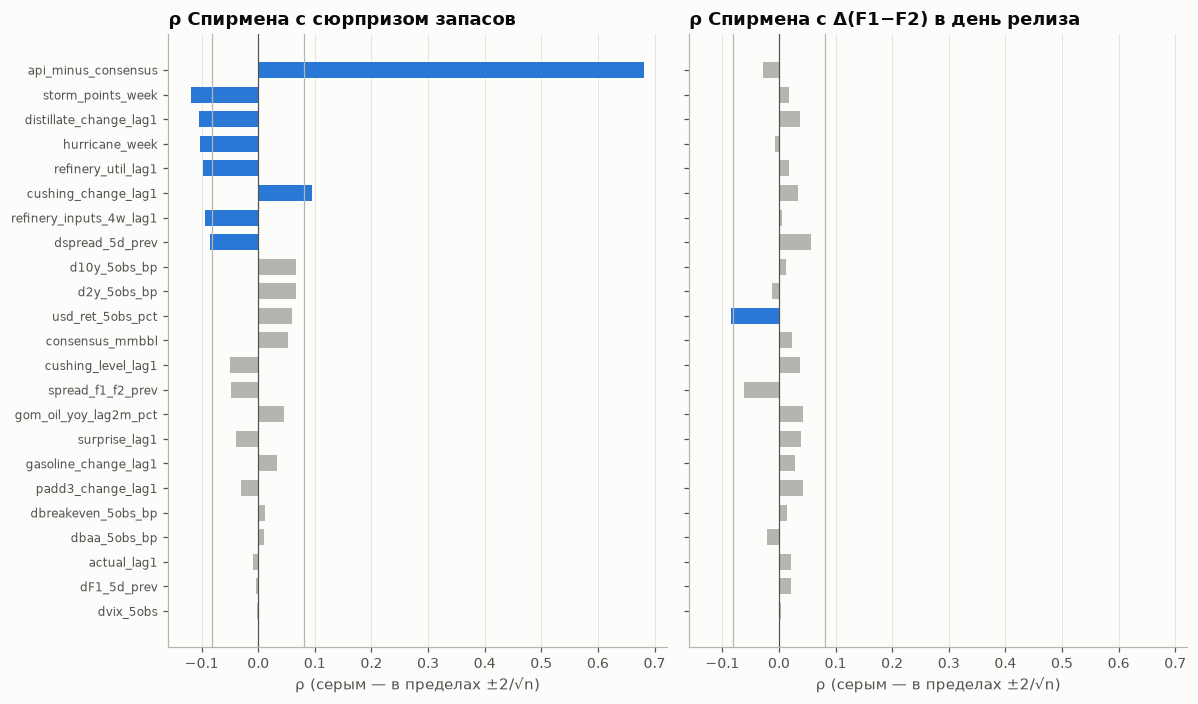

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True, sharex=True)
order = rho_surprise.index[::-1]
for ax, table, title in ((axes[0], rho_surprise, "с сюрпризом запасов"), (axes[1], rho_spread, "с Δ(F1−F2) в день релиза")):
    values = table["rho"].reindex(order)
    n = table["n"].median()
    colors = [u.SERIES[0] if abs(v) > 2 / np.sqrt(n) else u.NEUTRAL for v in values]
    ax.barh(range(len(values)), values, color=colors, height=0.65)
    ax.axvline(0, color=u.INK_MUTED, linewidth=0.8)
    for edge in (-2 / np.sqrt(n), 2 / np.sqrt(n)):
        ax.axvline(edge, color=u.NEUTRAL, linewidth=0.8)
    ax.set_title(f"ρ Спирмена {title}")
    ax.set_xlabel("ρ (серым — в пределах ±2/√n)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), order, fontsize=8)
plt.tight_layout()
plt.show()

Корреляция по штормам держится на немногих неделях — проверим напрямую средние сюрпризы.

In [10]:
storm = weekly.dropna(subset=["hurricane_week"])
groups = {
    "ураган в прямоугольнике": storm.loc[storm["hurricane_week"] == 1, "surprise_mmbbl"],
    "шторм без урагана": storm.loc[(storm["storm_points_week"] > 0) & (storm["hurricane_week"] == 0), "surprise_mmbbl"],
    "без шторма": storm.loc[storm["storm_points_week"] == 0, "surprise_mmbbl"],
}
storm_table = pd.DataFrame(
    {name: {"недель": len(v), "среднее": v.mean(), "медиана": v.median(), "доля < 0": (v < 0).mean()} for name, v in groups.items()},
).T
mw_hu = stats.mannwhitneyu(groups["ураган в прямоугольнике"], groups["без шторма"])
mw_any = stats.mannwhitneyu(pd.concat([groups["ураган в прямоугольнике"], groups["шторм без урагана"]]), groups["без шторма"])
print(f"Mann–Whitney: ураган vs без шторма p = {mw_hu.pvalue:.3f}; любой шторм vs без шторма p = {mw_any.pvalue:.3f}")
print(f"Порог Бонферрони для 23 признаков: {0.05 / len(FEATURES):.4f}")
storm_table.round(2)

Mann–Whitney: ураган vs без шторма p = 0.012; любой шторм vs без шторма p = 0.005
Порог Бонферрони для 23 признаков: 0.0022


,недель,среднее,медиана,доля < 0
ураган в прямоугольнике,14.0,-2.67,-1.51,0.71
шторм без урагана,17.0,-1.46,-2.03,0.59
без шторма,541.0,0.45,0.05,0.50


**Вывод.** Сильный признак сюрприза один — `API − консенсус` (ρ = 0.68). Остальные значимые на
уровне 5% слабые (|ρ| ≤ 0.12): шторм и ураган в прямоугольнике добычи за неделю отчёта (−0.12 и
−0.10), изменение дистиллятов и загрузка НПЗ прошлой недели (−0.11 и −0.10), ΔCushing прошлой недели
(+0.10), изменение переработки за 4 недели (−0.09), same-contract Δспрэда за 5 дней (−0.09).
С поправкой Бонферрони (p < 0.0022) значим только API. Прошлый факт, прошлый сюрприз, уровень
спрэда и макро-изменения — около нуля.

Ураганы — самый содержательный из слабых сигналов: в 14 неделях с ураганом средний сюрприз
−2.67 млн барр. (71% отрицательных) против +0.45 в 541 неделе без штормов (Mann–Whitney p = 0.012).
По этим 14 неделям консенсус недооценивает снижение запасов при ураганах — это как раз тип событий,
который должен ловить новостной граф.

Реакцию спрэда в день релиза не объясняет ни один признак (|ρ| ≤ 0.09; единственный p < 0.05 —
USD, при 23 проверках ожидаемо случайный). ΔF1 в день релиза связан с `API − консенсус`
(ρ = −0.12), как и в ноутбуке 04.

## 5. Коллинеарность признаков

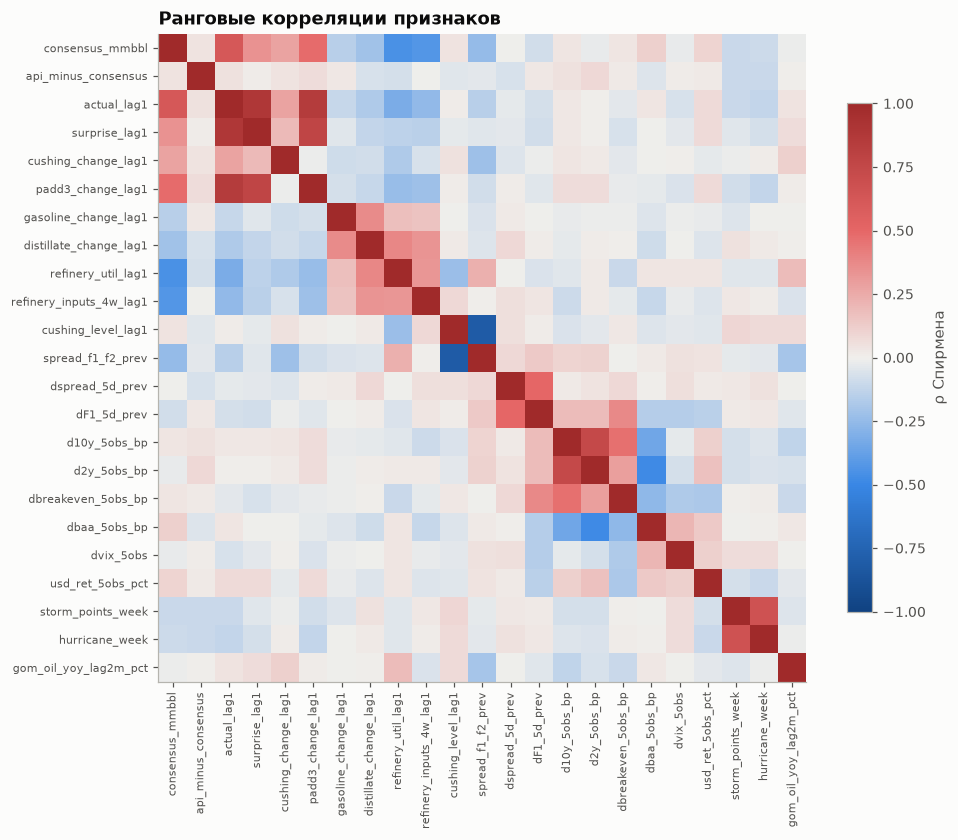

,level_0,level_1,rho
49,actual_lag1,surprise_lag1,0.887
51,actual_lag1,padd3_change_lag1,0.849
241,cushing_level_lag1,spread_f1_f2_prev,-0.805
74,surprise_lag1,padd3_change_lag1,0.766
337,d10y_5obs_bp,d2y_5obs_bp,0.738
481,storm_points_week,hurricane_week,0.667
2,consensus_mmbbl,actual_lag1,0.614
289,dspread_5d_prev,dF1_5d_prev,0.503
362,d2y_5obs_bp,dbaa_5obs_bp,-0.483
5,consensus_mmbbl,padd3_change_lag1,0.478


In [11]:
corr = weekly[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
image = ax.imshow(corr.to_numpy(), cmap=u.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.75, label="ρ Спирмена")
ax.set_title("Ранговые корреляции признаков")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs.loc[pairs["rho"].abs().sort_values(ascending=False).index].head(10).round(3)

**Вывод.** Сильные пары: прошлый факт и прошлый сюрприз (0.89), прошлый факт и ΔPADD3 прошлой
недели (0.85 — национальное изменение в основном и есть PADD3), уровень Cushing и спрэд F1−F2
(−0.81, как в ноутбуке 04), Δ10y и Δ2y (0.74). Консенсус коррелирует с прошлым фактом (0.61):
аналитики во многом опираются на прошлую неделю, хотя прошлый факт сюрприз не предсказывает. Для
линейных моделей из каждой пары оставлять один признак.

## 6. Устойчивость по периодам

ρ Спирмена с сюрпризом для признаков, значимых на полном периоде, в трёх режимах:
2015–2019, 2020–2022 (COVID, SPR), 2023–2026 (test).

In [12]:
periods = {
    "2015–2019": weekly["release_date"] < "2020-01-01",
    "2020–2022": weekly["release_date"].between("2020-01-01", "2022-12-31"),
    "2023–2026": weekly["release_date"] >= "2023-01-01",
}
significant = rho_surprise.index[rho_surprise["p"] < 0.05]
stability = pd.DataFrame(
    {
        name: {
            f: stats.spearmanr(*weekly.loc[mask, [f, "surprise_mmbbl"]].dropna().to_numpy().T)[0]
            for f in significant
        }
        for name, mask in periods.items()
    },
)
stability["полный период"] = rho_surprise.loc[significant, "rho"]
stability.round(3)

,2015–2019,2020–2022,2023–2026,полный период
api_minus_consensus,0.664,0.751,0.654,0.681
storm_points_week,-0.042,-0.191,-0.142,-0.119
distillate_change_lag1,-0.082,-0.119,-0.117,-0.105
hurricane_week,-0.100,-0.092,-0.114,-0.103
refinery_util_lag1,-0.198,-0.010,-0.112,-0.097
cushing_change_lag1,0.118,0.019,0.141,0.095
refinery_inputs_4w_lag1,-0.100,-0.136,-0.066,-0.093
dspread_5d_prev,-0.001,-0.176,-0.081,-0.086


**Вывод.** Устойчив только `API − консенсус` (ρ от 0.65 до 0.75 во всех трёх периодах). Слабые
признаки нестабильны: загрузка НПЗ −0.20 в 2015–2019 и −0.01 в 2020–2022; ΔCushing 0.12, 0.02 и
0.14; Δспрэда за 5 дней около нуля в 2015–2019 и −0.18 в 2020–2022. Штормовые признаки отрицательны
во всех периодах (от −0.04 до −0.19).

## 7. Сохранение таблицы

In [13]:
DESCRIPTION = {
    "release_date": "дата релиза EIA (Myfxbook)",
    "period": "пятница — конец недели отчёта",
    "actual_mmbbl": "ΔStocks нефти, первая публикация, млн барр.",
    "consensus_mmbbl": "консенсус Myfxbook, млн барр.",
    "surprise_mmbbl": "ТАРГЕТ: actual − consensus, млн барр.",
    "api_mmbbl": "API за неделю отчёта (вторник 16:30 ET), млн барр.",
    "api_minus_consensus": "API − консенсус, млн барр.",
    "actual_lag1": "факт прошлого релиза (первая публикация)",
    "surprise_lag1": "сюрприз прошлого релиза",
    "cushing_change_lag1": "ΔCushing за прошлую неделю отчёта (EIA, пересмотренные)",
    "padd3_change_lag1": "ΔPADD3 за прошлую неделю отчёта",
    "gasoline_change_lag1": "Δбензина за прошлую неделю отчёта",
    "distillate_change_lag1": "Δдистиллятов за прошлую неделю отчёта",
    "refinery_util_lag1": "загрузка НПЗ за прошлую неделю, %",
    "refinery_inputs_4w_lag1": "изменение переработки за 4 недели до прошлой недели, тыс. барр./сут",
    "cushing_level_lag1": "запасы Cushing на конец прошлой недели, млн барр.",
    "spread_f1_f2_prev": "F1−F2 на закрытие торгового дня перед релизом, $",
    "dspread_5d_prev": "same-contract Δ(F1−F2) за 5 торговых дней до дня перед релизом, $",
    "dF1_5d_prev": "same-contract ΔF1 за 5 торговых дней до дня перед релизом, $",
    "roll_window_release": "день релиза в окне ролла Barchart (2–6 торговых дней до экспирации)",
    "dspread_release": "ИСХОД: same-contract Δ(F1−F2) в день релиза, $",
    "dF1_release": "ИСХОД: same-contract ΔF1 в день релиза, $",
    "d10y_5obs_bp": "Δ10y за 5 наблюдений на R−2 рабочих дня, б.п.",
    "d2y_5obs_bp": "Δ2y за 5 наблюдений на R−2, б.п.",
    "dbreakeven_5obs_bp": "Δbreakeven 10y за 5 наблюдений на R−2, б.п.",
    "dbaa_5obs_bp": "ΔBAA-спрэда за 5 наблюдений на R−2, б.п.",
    "dvix_5obs": "ΔVIX за 5 наблюдений на R−1",
    "usd_ret_5obs_pct": "доходность USD broad за 5 наблюдений на пятницу недели отчёта, %",
    "storm_points_week": "точек трека HURDAT2 в прямоугольнике добычи за неделю отчёта (best track)",
    "hurricane_week": "был ли ураган (HU) в прямоугольнике за неделю отчёта",
    "storm_max_wind_kt": "максимальный ветер шторма в прямоугольнике за неделю, уз.",
    "gom_oil_yoy_lag2m_pct": "добыча нефти в заливе (BSEE) год к году за месяц на 2 раньше релиза, %",
    "split": "train (до 2022-12-31) / test (с 2023-01-01)",
}
assert set(DESCRIPTION) == set(weekly.columns), set(weekly.columns) ^ set(DESCRIPTION)
weekly.to_parquet(DERIVED / "weekly_frame.parquet", index=False)
print(f"{DERIVED / 'weekly_frame.parquet'}: {weekly.shape}")
pd.Series(DESCRIPTION, name="описание").to_frame()

/home/lllyasch/Projects/oil-news-graph/eda/data/derived/weekly_frame.parquet: (616, 33)


,описание
release_date,дата релиза EIA (Myfxbook)
period,пятница — конец недели отчёта
actual_mmbbl,"ΔStocks нефти, первая публикация, млн барр."
consensus_mmbbl,"консенсус Myfxbook, млн барр."
surprise_mmbbl,"ТАРГЕТ: actual − consensus, млн барр."
api_mmbbl,"API за неделю отчёта (вторник 16:30 ET), млн барр."
api_minus_consensus,"API − консенсус, млн барр."
actual_lag1,факт прошлого релиза (первая публикация)
surprise_lag1,сюрприз прошлого релиза
cushing_change_lag1,"ΔCushing за прошлую неделю отчёта (EIA, пересмотренные)"


## Итоги

- **Таблица:** 616 релизов × 33 колонки в `eda/data/derived/weekly_frame.parquet`; каждый признак
  известен до релиза по правилам раздела 1. Полных строк 512 (2016-03 – 2025-12), без штормов и
  BSEE — 604 (2015-04 – 2026-11).
- **Сюрприз объясняет по сути один признак** — `API − консенсус` (ρ = 0.68, устойчив по периодам).
- **История EIA, рынок и макро** дают только слабые и нестабильные связи (|ρ| ≤ 0.12); ни одна не
  проходит поправку на множественные сравнения.
- **Ураганы в заливе:** средний сюрприз −2.67 против +0.45 без штормов (p = 0.012, 14 недель) —
  пример события, которое консенсус недооценивает, и аргумент за событийные признаки из новостей.
- **Реакцию спрэда в день релиза** на дневных закрытиях не объясняет ничего, включая сам сюрприз
  (ноутбук 04).
- **Перед моделью:** заменить best track HURDAT2 оперативными данными NHC, уточнить лаг публикации
  BSEE, учесть, что лаговые признаки EIA (кроме национального факта) взяты из пересмотренных данных.